# Double descent in a toy model of superposition: 3D sweep (m = 3)

Sweep over the number of training points T for a ReLU-output toy autoencoder (Henighan et al., 2023). For each T we train a model and record the 3D hidden vectors of the training points, train and test loss, and two dimensionality metrics, checkpointing to HDF5.

**Setup:** n = 10,000 features, m = 3, sparsity S = 0.999, T from 25 to 8,000 in steps of 25 (320 values), best of k = 3 seeds per T, 50,000 steps.

**How the published data was produced.** Because of compute limits the sweep was not run in one session. An initial run failed after T = 1495 and its partial results were not used. The data was then generated in two sessions with identical settings (T = 25 to 5,000 and T = 5,025 to 8,000), and the two output files were merged into `sweep_merged.h5`. This notebook shows the consolidated configuration. Each T uses a fixed dataset seed (`DATASET_SEED_BASE + T`) and fixed model seeds, so results should not depend on which session produced them, but this consolidated notebook has not been run end to end. `sweep_merged.h5` was checked to contain all 320 values (T = 25 to 8,000, stride 25, m = 3).

## 1. Setup
Imports, GPU check, and global seeds. TF32 matrix multiplication is enabled on CUDA for speed. The code falls back to CPU if no GPU is found, but the full sweep is impractical without one.

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import itertools
from tqdm.notebook import tqdm

In [4]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

    # Allow TF32 matmuls on Ampere+/T4 — free speedup, negligible precision cost here
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    print("No GPU detected — go to Runtime > Change runtime type > T4 GPU")

Using device: cuda
GPU: NVIDIA GeForce RTX 2080 Ti


## 2. Data generation
Each training point is a sparse vector in R^n. Every feature is active independently with probability 1 − S (here 0.001, so about 10 active features per point), active values are drawn uniformly from [0, 1], and each point is then L2-normalised to unit norm. Passing `seed` makes a dataset reproducible; the sweep uses `DATASET_SEED_BASE + T`.

In [5]:
def generate_dataset(T, n_features=10_000, sparsity=0.999, seed=None):
    if seed is not None:
        torch.manual_seed(seed)

    mask = torch.bernoulli(
        torch.full((T, n_features), 1 - sparsity, device=device)
    )
    values = torch.rand(T, n_features, device=device)
    X = mask * values

    norms = X.norm(dim=1, keepdim=True).clamp(min=1e-8)
    X = X / norms

    return X

## 3. Model
A one-layer autoencoder with tied weights and a ReLU output: h = Wx, x̂ = ReLU(Wᵀh + b), with W ∈ R^(m×n) (Xavier-uniform init) and b ∈ R^n (zero init). With m much smaller than n, the model has to store features in superposition. `get_hidden` returns h for a batch without tracking gradients.

In [6]:
class ReLUOutputModel(nn.Module):
    def __init__(self, n_features, m_hidden):
        super().__init__()
        self.n_features = n_features
        self.m_hidden = m_hidden
        self.W = nn.Parameter(nn.init.xavier_uniform_(torch.empty(m_hidden, n_features)))
        self.b = nn.Parameter(torch.zeros(n_features))

    def forward(self, x):
        h = x @ self.W.T
        x_hat = torch.relu(h @ self.W + self.b)

        return x_hat

    def get_hidden(self, x):
        with torch.no_grad():
            return x @ self.W.T

## 4. Training
Full-batch training on all T points with mean-squared-error loss over every entry. AdamW (peak LR 1e-3, weight decay 1e-2), 50,000 steps: 2,500 linear warm-up steps, then cosine decay to zero.

`train_best_of_k` trains k models from initialisation seeds 0 to k−1 (the same seeds for every T) and keeps the one with the lowest final **training** loss. Selecting on training loss can favour memorising solutions in the transition region; see the README.

In [7]:
def train_model(model, X_train, n_steps=50_000, warmup_steps=2_500, peak_lr=1e-3, weight_decay=1e-2):
    model.train()
    optimizer = optim.AdamW(model.parameters(), lr=peak_lr, weight_decay=weight_decay)

    def lr_lambda(step):
        if step < warmup_steps:
            return step / warmup_steps

        progress = (step - warmup_steps) / max(1, n_steps - warmup_steps)
        return 0.5 * (1 + np.cos(np.pi * progress))

    scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    X_train = X_train.to(device, non_blocking=True)
    train_losses = []

    for step in range(n_steps):
        optimizer.zero_grad(set_to_none=True)

        x_hat = model(X_train)

        loss = ((X_train - x_hat) ** 2).mean()

        loss.backward()
        optimizer.step()
        scheduler.step()

        train_losses.append(loss.item())

    return train_losses

In [8]:
def train_best_of_k(n_features, m_hidden, X_train, k=3, **train_kwargs):
    best_model = None
    best_loss = float('inf')

    for seed in range(k):
        torch.manual_seed(seed)

        model = ReLUOutputModel(n_features, m_hidden).to(device)

        losses = train_model(model, X_train, **train_kwargs)
        final_loss = losses[-1]

        if final_loss < best_loss:
            best_loss = final_loss
            best_model = model

    return best_model, best_loss

# Dimensionality Metrics
Dimensionality metrics (legacy, kept for reproducibility).
feature_dimensionality and datapoint_dimensionality are computed for every T and stored as D_feat and D_data in the .h5 files and in data.js, where the dashboards plot them. They are not used in the reported results. They are a variant of the dimensionality measure from Elhage et al. (2022) and Henighan et al. (2023), not an exact reimplementation.

**A replacement metric is in development, intended to generalize to n dimensions and to track feature collapse more reliably. It is not part of this release.**

In [9]:
def feature_dimensionality(model):
    W = model.W.detach()
    cols = W.T

    norms_sq = (cols**2).sum(dim=1)
    norms = norms_sq.sqrt().clamp(min=1e-8)
    cols_hat = cols / norms.unsqueeze(1)

    cos_sim = cols_hat @ cols_hat.T
    denom = (cos_sim**2).sum(dim=1)

    D = norms_sq**2 / denom.clamp(min=1e-8)
    return D.mean().item()

In [10]:
def datapoint_dimensionality(model, X_train):
    with torch.no_grad():
        H = model.get_hidden(X_train.to(device))

    norms_sq = (H**2).sum(dim=1)
    norms = norms_sq.sqrt().clamp(min=1e-8)
    H_hat = H / norms.unsqueeze(1)

    cos_sim = H_hat @ H_hat.T
    denom = (cos_sim**2).sum(dim=1)
    D = norms_sq**2 / denom.clamp(min=1e-8)
    return D.mean().item()

## 5. Test loss
`compute_test_loss` evaluates the same MSE on 5,000 freshly generated points that the model has not seen. A loss of 1/n = 1e-4 is what an all-zeros prediction would score, so test loss near 1e-4 means no useful generalisation.

In [11]:
def compute_test_loss(model, n_features=10_000, sparsity=0.999, T_test=5_000):
    """Evaluate model on a fresh test set it has never seen."""
    model.eval()
    with torch.no_grad():
        X_test = generate_dataset(T_test, n_features, sparsity).to(device)
        x_hat  = model(X_test)
        loss   = ((X_test - x_hat) ** 2).mean().item()
    return loss

## 6. Hidden geometry (demo)
A quick visual check, not part of the sweep: trains models at T = 50, 500 and 5,000 and scatters the 3D hidden vectors h_i = W x_i of the training points. It trains 3 values of T × 3 seeds at full fidelity, so it is slow.

In [12]:
from mpl_toolkits.mplot3d import Axes3D

def plot_hidden_geometry(T_values, n_features=10_000, m_hidden=3, sparsity=0.999, k_seeds=3):
    n_cols = len(T_values)

    fig = plt.figure(figsize=(5 * n_cols, 5))
    axes = [
        fig.add_subplot(1, n_cols, i + 1, projection="3d")
        for i in range(n_cols)
    ]

    if n_cols == 1:
        axes = [axes[0]]

    for ax, T in zip(axes, T_values):
        print(f"  Training T={T}...")

        X_train = generate_dataset(T, n_features, sparsity)
        model, _ = train_best_of_k(
            n_features,
            m_hidden,
            X_train,
            k=k_seeds
        )

        # Hidden representations (T × 3)
        H = model.get_hidden(X_train).cpu().numpy()

        ax.scatter(
            H[:, 0],
            H[:, 1],
            H[:, 2],
            alpha=0.6,
            s=10,
            color="steelblue"
        )

        ax.set_title(f"T = {T}", fontsize=13)

        ax.set_xlabel("h₁")
        ax.set_ylabel("h₂")
        ax.set_zlabel("h₃")

        # Equal scaling for all three axes
        mins = H.min(axis=0)
        maxs = H.max(axis=0)

        center = (mins + maxs) / 2
        radius = (maxs - mins).max() / 2

        ax.set_xlim(center[0] - radius, center[0] + radius)
        ax.set_ylim(center[1] - radius, center[1] + radius)
        ax.set_zlim(center[2] - radius, center[2] + radius)

    fig.suptitle(
        "Hidden Geometry of Training Points $h_i = Wx_i$\n"
        "(m=3, n=10,000, S=0.999)",
        fontsize=14,
        y=0.98,
    )

    plt.tight_layout()
    plt.show()

Plotting hidden geometry for T = 50, 500, 5000...
  Training T=50...
  Training T=500...
  Training T=5000...


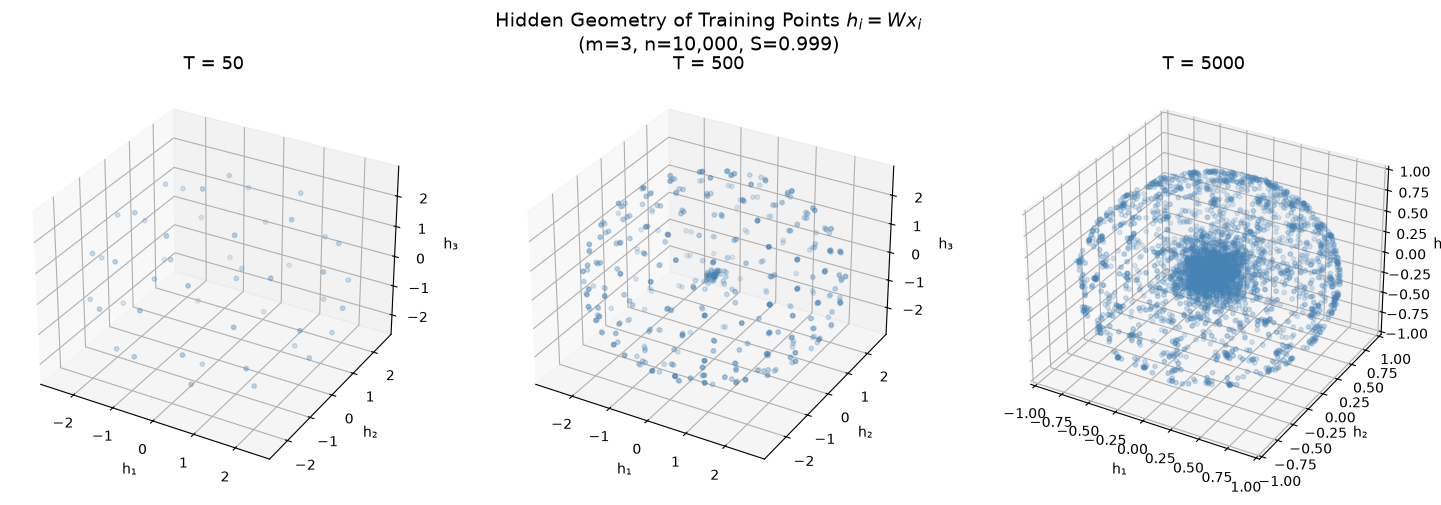

In [14]:
print("Plotting hidden geometry for T = 50, 500, 5000...")
plot_hidden_geometry(T_values=[50, 500, 5000], k_seeds=3)

## 7. Sweep configuration
All sweep settings live in this cell. Training settings match the defaults of `train_model`. Each dataset is seeded with `DATASET_SEED_BASE + T`, so rerunning a T regenerates the same training set. Output paths are relative to this notebook's folder.

In [ ]:
import h5py
import json
import os
import time

# ============================================================
# SWEEP CONFIGURATION — change anything here, nothing else
# ============================================================

# --- Grid ---
T_MIN   = 25
T_MAX   = 8000
STRIDE  = 25
T_GRID  = list(range(T_MIN, T_MAX + 1, STRIDE))

# --- Model / data ---
N_FEATURES = 10_000
M_HIDDEN   = 3
SPARSITY   = 0.999
K_SEEDS    = 3

# --- Training ---
TRAIN_KWARGS = dict(
    n_steps=50_000,
    warmup_steps=2_500,
    peak_lr=1e-3,
    weight_decay=1e-2,
)

# --- Test loss ---
T_TEST = 5_000

# --- Storage ---
H5_PATH      = "sweep_merged.h5"
DATA_JS_PATH = "data.js"

# --- Dataset generation seed ---
DATASET_SEED_BASE = 0

## 8. HDF5 checkpointing
Results are appended to the HDF5 file after every T, so an interrupted sweep loses at most one T. Layout:

- `results/T_<T>/H`: hidden vectors of the T training points, shape (T, m), gzip-compressed
- attributes on each `T_<T>` group: `T`, `train_loss`, `test_loss`, `D_feat`, `D_data`, `wall_time` (seconds)

`get_completed_Ts` lets the sweep loop skip anything already saved. If the output file already exists the sweep resumes; to start fresh, point `H5_PATH` at a new file.

In [16]:
def get_completed_Ts(h5_path):
    """Returns the set of T values already saved in the HDF5 file."""
    if not os.path.exists(h5_path):
        return set()
    with h5py.File(h5_path, "r") as f:
        if "results" not in f:
            return set()
        return set(int(k.split("_")[1]) for k in f["results"].keys())

def save_T_result(h5_path, T, H, train_loss, test_loss, D_feat, D_data, wall_time):
    """Appends a single T's results to the HDF5 file immediately (incremental checkpoint)."""
    with h5py.File(h5_path, "a") as f:
        grp = f.require_group("results")
        sub = grp.create_group(f"T_{T}")
        sub.create_dataset("H", data=H, compression="gzip")
        sub.attrs["T"] = T
        sub.attrs["train_loss"] = train_loss
        sub.attrs["test_loss"] = test_loss
        sub.attrs["D_feat"] = D_feat
        sub.attrs["D_data"] = D_data
        sub.attrs["wall_time"] = wall_time

## 9. Sweep loop
For each T in the grid (skipping completed ones): generate the training set, train the best of k models, compute the hidden vectors, test loss and dimensionality metrics, and checkpoint. With H5_PATH pointing at the published sweep_merged.h5, all 320 values are already present, so this cell finishes immediately. Point H5_PATH at a new file to recompute (days of GPU time). Per-T wall_time is stored in the .h5 attributes. No log is included because the data came from separate sessions (see the top of this notebook).

In [ ]:
completed = get_completed_Ts(H5_PATH)
print(f"Resuming: {len(completed)}/{len(T_GRID)} T-values already done.")

sweep_start = time.time()

for idx, T in enumerate(T_GRID):
    if T in completed:
        continue

    t0 = time.time()
    print(f"[{idx+1}/{len(T_GRID)}] Training T={T} ...")

    X_train = generate_dataset(
        T, N_FEATURES, SPARSITY, seed=DATASET_SEED_BASE + T
    )

    model, best_loss = train_best_of_k(
        N_FEATURES, M_HIDDEN, X_train, k=K_SEEDS, **TRAIN_KWARGS
    )

    H = model.get_hidden(X_train).cpu().numpy()

    test_loss = compute_test_loss(
        model, N_FEATURES, SPARSITY, T_TEST
    )
    D_feat = feature_dimensionality(model)
    D_data = datapoint_dimensionality(model, X_train)

    wall_time = time.time() - t0

    save_T_result(H5_PATH, T, H, best_loss, test_loss, D_feat, D_data, wall_time)

    elapsed = time.time() - sweep_start
    print(f"    done in {wall_time/60:.1f} min | train_loss={best_loss:.4e} "
          f"test_loss={test_loss:.4e} | total elapsed {elapsed/3600:.2f} hr")

print(f"\nSweep complete. Total time: {(time.time()-sweep_start)/3600:.2f} hours.")

## 10. Export
Converts sweep_merged.h5 into data.js (const SWEEP = [...]), which dashboard_3d.html loads. Each entry holds T, the three hidden coordinates (H1, H2, H3), the losses, and the two dimensionality values. The file is about 80 MB, so it is distributed as a release asset rather than committed (see README).

In [ ]:
import json

def export_to_js(h5_path, out_path):
    with h5py.File(h5_path, "r") as f:
        grp = f["results"]
        T_values = sorted(int(k.split("_")[1]) for k in grp.keys())

        sweep_data = []

        for T in T_values:
            sub = grp[f"T_{T}"]

            H = sub["H"][:]

            sweep_data.append({
                "T": T,

                "H1": H[:,0].tolist(),
                "H2": H[:,1].tolist(),
                "H3": H[:,2].tolist(),

                "train_loss": float(sub.attrs["train_loss"]),
                "test_loss": float(sub.attrs["test_loss"]),
                "D_feat": float(sub.attrs["D_feat"]),
                "D_data": float(sub.attrs["D_data"]),
            })

    with open(out_path, "w") as f:
        f.write("const SWEEP = ")
        json.dump(sweep_data, f)
        f.write(";")

    print(
        f"Exported {len(sweep_data)} T-values "
        f"to {out_path} "
        f"({os.path.getsize(out_path)/1e6:.2f} MB)"
    )

export_to_js(H5_PATH, DATA_JS_PATH)